# EDA — Popularity Baseline | Proyek Sistem Rekomendasi Tiro

**Mata kuliah:** 12S4054 Sistem Rekomendasi  
**Dataset:** Amazon Reviews 2023 — Musical Instruments (5-core)  
**Tujuan notebook:** Melakukan *Exploratory Data Analysis* (EDA) yang sistematis dan mendalam terhadap dataset interaksi dan metadata produk, sebagai landasan pengembangan sistem rekomendasi berbasis popularitas (*Popularity-Based Recommendation*).

---

## Struktur Analisis

| Seksi | Topik |
|-------|-------|
| 1 | Setup & Load Dataset |
| 2 | Pengenalan Dataset |
| 3 | Kualitas Data |
| 4 | Statistik Deskriptif |
| 5 | Distribusi Rating |
| 6 | Analisis Temporal |
| 7 | Analisis Pengguna |
| 8 | Analisis Item & Long-Tail |
| 9 | Sparsity & Matriks Interaksi |
| 10 | Analisis Popularitas |
| 11 | Candidate Set & Data Validasi |
| 12 | Hubungan Antarvariabel |
| 13 | Ringkasan Temuan Utama |
| 14 | Implikasi terhadap Model |

> **Catatan reprodusibilitas:** Jalankan sel dari atas ke bawah secara berurutan. Dataset harus tersedia di folder `data/` (lokal) atau diunggah ke `/content/data/` (Google Colab).

---
## 1. Setup & Load Dataset

In [1]:
# == Import library ==
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

warnings.filterwarnings('ignore')

# == Style konsisten untuk semua grafik ==
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
})

# == Path discovery: mendukung lokal dan Google Colab ==
SEARCH_ROOTS = [
    Path('.'),
    Path('./data'),
    Path('./MAIN DATA'),
    Path('/content'),
    Path('/content/data'),
]

def find_file(filename: str) -> Path:
    """Mencari file di berbagai direktori kandidat."""
    for root in SEARCH_ROOTS:
        if root.exists():
            matches = list(root.rglob(filename))
            if matches:
                return matches[0]
    raise FileNotFoundError(
        f"'{filename}' tidak ditemukan. "
        "Pastikan dataset tersedia di folder data/ lalu jalankan ulang."
    )

# == Load interactions_train.csv ==
train_path = find_file('interactions_train.csv')
train = pd.read_csv(train_path)

required_cols = {'user_id', 'item_id', 'rating'}
assert required_cols.issubset(train.columns), (
    f"Kolom wajib tidak ditemukan: {required_cols - set(train.columns)}"
)

print(f"Loaded: {train_path}")
print(f"Shape : {train.shape[0]:,} baris x {train.shape[1]} kolom")
print(f"Kolom : {list(train.columns)}")

Loaded: data\interactions_train.csv
Shape : 427,957 baris x 4 kolom
Kolom : ['user_id', 'item_id', 'rating', 'timestamp']


---
## 2. Pengenalan Dataset

### 2.1 Deskripsi Kolom

Dataset `interactions_train.csv` merekam interaksi pengguna–produk pada platform Amazon untuk kategori **Musical Instruments** (5-core: setiap pengguna dan produk memiliki minimal 5 ulasan).

| Kolom | Tipe | Deskripsi |
|-------|------|-----------|
| `user_id` | string | Identifikasi unik pengguna Amazon |
| `item_id` | string | Identifikasi unik produk (ASIN Amazon) |
| `rating` | float | Rating pengguna terhadap produk (skala 1–5) |
| `timestamp` | int | Waktu interaksi dalam format Unix timestamp (milidetik) |

**Aturan evaluasi proyek:**
- Rating ≥ 4 dianggap **relevan** (interaksi positif)
- Cutoff rekomendasi: Top-10
- **Long-tail:** item dengan jumlah interaksi training ≤ 5
- Item yang sudah dilihat pengguna di training **dikeluarkan** dari rekomendasi

In [2]:
print('=== 5 baris pertama dataset ===')
display(train.head())

print('\n=== Tipe data per kolom ===')
print(train.dtypes.to_string())

print('\n=== Info ringkas ===')
train.info()

=== 5 baris pertama dataset ===


,user_id,item_id,rating,timestamp
0,AFRGJMSUHGKN6E36WF7NUXIQVXVQ,B07YM5ZHS9,4.0,1053991604000
1,AE4H7ZEPV4JIYCPBM23XHY57FHGQ,0634031600,5.0,1058971915000
2,AFJWPVVW4BE435ILB7TOM4PQZHEA,B0002GO864,4.0,1091480547000
3,AGFVP2RIKQMCJOWPEFL2YOQKSUGA,B071GLQQTW,5.0,1092714535000
4,AGFVP2RIKQMCJOWPEFL2YOQKSUGA,B0002F79E8,5.0,1093033600000



=== Tipe data per kolom ===
user_id          str
item_id          str
rating       float64
timestamp      int64

=== Info ringkas ===
<class 'pandas.DataFrame'>
RangeIndex: 427957 entries, 0 to 427956
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   user_id    427957 non-null  str    
 1   item_id    427957 non-null  str    
 2   rating     427957 non-null  float64
 3   timestamp  427957 non-null  int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 13.1 MB


---
## 3. Kualitas Data

Bagian ini memeriksa:
- **Missing values** — nilai kosong per kolom
- **Duplikasi baris** — baris identik sepenuhnya
- **Duplikasi interaksi** — pasangan (user, item) yang muncul lebih dari sekali
- **Nilai tidak wajar** — rating di luar rentang 1–5

In [3]:
# 3.1 Missing values
missing = train.isna().sum()
missing_pct = (missing / len(train) * 100).round(4)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct})
print('Missing values per kolom:')
display(missing_df)

if missing.sum() == 0:
    print('OK: Tidak ada missing value pada dataset training.')
else:
    print(f'PERHATIAN: Total missing values: {missing.sum():,}')

Missing values per kolom:


,missing_count,missing_%
user_id,0,0.0
item_id,0,0.0
rating,0,0.0
timestamp,0,0.0


OK: Tidak ada missing value pada dataset training.


In [4]:
# 3.2 Duplikasi
n_dup_rows = train.duplicated().sum()
print(f'Jumlah baris duplikat (identik sepenuhnya): {n_dup_rows:,}')

n_unique_pairs = train[['user_id', 'item_id']].drop_duplicates().shape[0]
n_dup_pairs = len(train) - n_unique_pairs
print(f'Jumlah interaksi total                  : {len(train):,}')
print(f'Jumlah pasangan (user, item) unik       : {n_unique_pairs:,}')
print(f'Jumlah interaksi duplikat (user, item)  : {n_dup_pairs:,} '
      f'({n_dup_pairs / len(train) * 100:.2f}% dari total)')

if n_dup_pairs > 0:
    print('PERHATIAN: Ada pasangan (user, item) yang muncul lebih dari sekali.')
    print('  Pada langkah perhitungan popularitas, deduplikasi akan diterapkan.')
else:
    print('OK: Setiap pasangan (user, item) hanya muncul tepat satu kali.')

Jumlah baris duplikat (identik sepenuhnya): 0


Jumlah interaksi total                  : 427,957
Jumlah pasangan (user, item) unik       : 427,957
Jumlah interaksi duplikat (user, item)  : 0 (0.00% dari total)
OK: Setiap pasangan (user, item) hanya muncul tepat satu kali.


In [5]:
# 3.3 Nilai tidak wajar pada kolom rating
valid_ratings = {1.0, 2.0, 3.0, 4.0, 5.0}
invalid_ratings = train[~train['rating'].isin(valid_ratings)]
print(f'Rating tidak wajar (di luar 1-5): {len(invalid_ratings):,}')

train['rating'] = pd.to_numeric(train['rating'], errors='coerce')
print(f'Rentang rating: {train["rating"].min()} - {train["rating"].max()}')
print(f'Nilai unik rating: {sorted(train["rating"].dropna().unique())}')

if len(invalid_ratings) == 0:
    print('OK: Semua nilai rating valid (1.0, 2.0, 3.0, 4.0, atau 5.0).')

Rating tidak wajar (di luar 1-5): 0
Rentang rating: 1.0 - 5.0
Nilai unik rating: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
OK: Semua nilai rating valid (1.0, 2.0, 3.0, 4.0, atau 5.0).


---
## 4. Statistik Deskriptif

Ringkasan numerik dan kategorikal seluruh kolom dataset.

In [6]:
# 4.1 Statistik numerik
print('=== Statistik deskriptif (kolom numerik) ===')
display(train.describe())

# 4.2 Statistik kategorikal
print('\n=== Ringkasan Dataset ===')
n_users  = train['user_id'].nunique()
n_items  = train['item_id'].nunique()
n_total  = len(train)

stats_summary = pd.DataFrame({
    'Metrik': [
        'Total interaksi',
        'Pengguna unik',
        'Item unik',
        'Rata-rata interaksi per pengguna',
        'Rata-rata interaksi per item',
        'Median interaksi per pengguna',
        'Median interaksi per item',
    ],
    'Nilai': [
        f'{n_total:,}',
        f'{n_users:,}',
        f'{n_items:,}',
        f'{n_total / n_users:.2f}',
        f'{n_total / n_items:.2f}',
        f'{train.groupby("user_id").size().median():.1f}',
        f'{train.groupby("item_id").size().median():.1f}',
    ]
})
display(stats_summary.set_index('Metrik'))

=== Statistik deskriptif (kolom numerik) ===


,rating,timestamp
count,427957.000000,4.279570e+05
mean,4.452690,1.502446e+12
std,1.035668,8.072511e+10
min,1.000000,1.053992e+12
25%,4.000000,1.442453e+12
50%,5.000000,1.508011e+12
75%,5.000000,1.571088e+12
max,5.000000,1.628643e+12



=== Ringkasan Dataset ===


,Nilai
Metrik,
Total interaksi,"427,957"
Pengguna unik,"54,483"
Item unik,"22,753"
Rata-rata interaksi per pengguna,7.85
Rata-rata interaksi per item,18.81
Median interaksi per pengguna,6.0
Median interaksi per item,8.0


---
## 5. Distribusi Rating

Dataset menggunakan skala rating 1–5. Distribusi rating menentukan seberapa besar proporsi interaksi yang dianggap **relevan** (rating ≥ 4) untuk sistem rekomendasi.

In [7]:
# Distribusi rating
rating_counts = train['rating'].value_counts(dropna=False).sort_index()
rating_pct    = (rating_counts / len(train) * 100).round(2)

rating_df = pd.DataFrame({'jumlah': rating_counts, 'persentase (%)': rating_pct})
print('Distribusi rating pada data training:')
display(rating_df)

positive_mask = train['rating'] >= 4
pct_positive  = positive_mask.mean() * 100
print(f'\nInteraksi positif (rating >= 4): {positive_mask.sum():,} ({pct_positive:.1f}%)')
print(f'Interaksi negatif (rating < 4) : {(~positive_mask).sum():,} ({100-pct_positive:.1f}%)')

Distribusi rating pada data training:


,jumlah,persentase (%)
rating,,
1.0,17486,4.09
2.0,14335,3.35
3.0,28578,6.68
4.0,64120,14.98
5.0,303438,70.90



Interaksi positif (rating >= 4): 367,558 (85.9%)
Interaksi negatif (rating < 4) : 60,399 (14.1%)


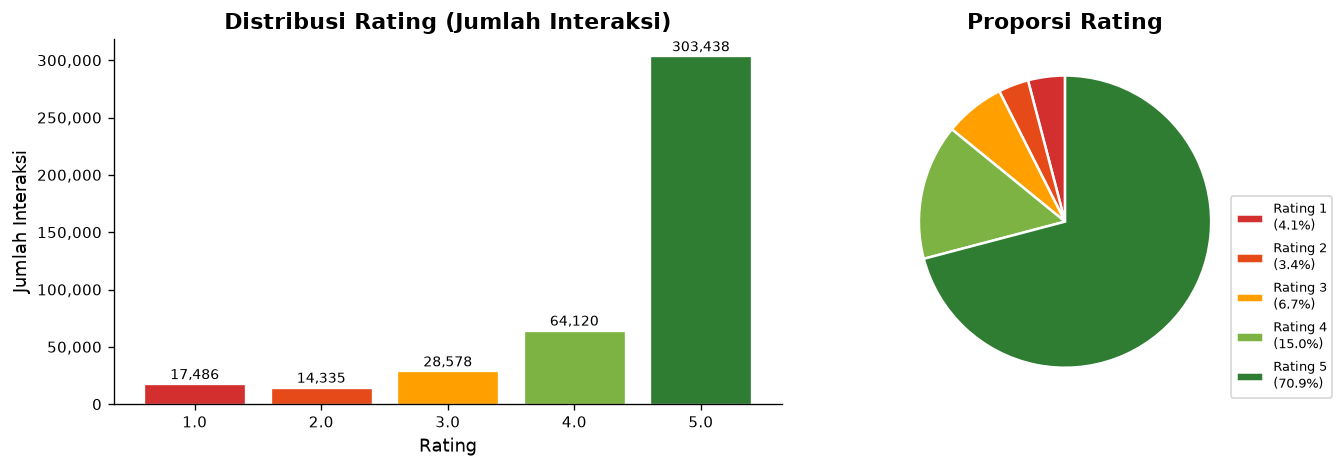


Interpretasi:
  Distribusi rating sangat miring ke kanan (right-skewed), dengan rating 5 mendominasi sekitar 70.9% seluruh interaksi.
  Hal ini umum terjadi pada data ulasan Amazon (positivity bias).
  Sebanyak 85.9% interaksi dianggap positif (rating >= 4), yang berarti sinyal untuk popularity baseline cukup kuat.


In [8]:
colors = ['#d32f2f', '#e64a19', '#ffa000', '#7cb342', '#2e7d32']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
bars = axes[0].bar(
    rating_counts.index.astype(str), rating_counts.values,
    color=colors, edgecolor='white', linewidth=0.8
)
for bar, val in zip(bars, rating_counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1500,
        f'{val:,}', ha='center', va='bottom', fontsize=8.5
    )
axes[0].set_title('Distribusi Rating (Jumlah Interaksi)', fontweight='bold')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Jumlah Interaksi')
axes[0].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f'{int(x):,}')
)

# Pie chart
pie_labels = [
    f'Rating {int(r)}\n({pct:.1f}%)'
    for r, pct in zip(rating_counts.index, rating_pct.values)
]
wedges, _ = axes[1].pie(
    rating_counts.values, colors=colors, startangle=90,
    wedgeprops=dict(linewidth=1.5, edgecolor='white')
)
axes[1].legend(wedges, pie_labels, loc='lower right', fontsize=8,
               bbox_to_anchor=(1.25, 0))
axes[1].set_title('Proporsi Rating', fontweight='bold')

plt.tight_layout()
plt.show()

print('\nInterpretasi:')
print(f'  Distribusi rating sangat miring ke kanan (right-skewed), dengan rating 5'
      f' mendominasi sekitar {rating_pct.get(5.0, 0):.1f}% seluruh interaksi.')
print(f'  Hal ini umum terjadi pada data ulasan Amazon (positivity bias).')
print(f'  Sebanyak {pct_positive:.1f}% interaksi dianggap positif (rating >= 4),'
      f' yang berarti sinyal untuk popularity baseline cukup kuat.')

---
## 6. Analisis Temporal

Kolom `timestamp` menyimpan waktu interaksi dalam format Unix timestamp (milidetik). Analisis ini bertujuan mengidentifikasi rentang waktu data dan distribusi temporal interaksi.

In [9]:
# Konversi timestamp ke datetime (deteksi satuan otomatis)
ts_median = train['timestamp'].median()
if ts_median > 1e12:
    train['datetime'] = pd.to_datetime(train['timestamp'], unit='ms')
else:
    train['datetime'] = pd.to_datetime(train['timestamp'], unit='s')

print('=== Rentang Waktu Data ===')
print(f'  Interaksi paling awal : {train["datetime"].min().strftime("%d %B %Y")}')
print(f'  Interaksi paling akhir: {train["datetime"].max().strftime("%d %B %Y")}')
durasi = (train['datetime'].max() - train['datetime'].min()).days
print(f'  Durasi rentang data   : {durasi:,} hari ({durasi / 365.25:.1f} tahun)')

=== Rentang Waktu Data ===
  Interaksi paling awal : 26 May 2003
  Interaksi paling akhir: 11 August 2021
  Durasi rentang data   : 6,651 hari (18.2 tahun)


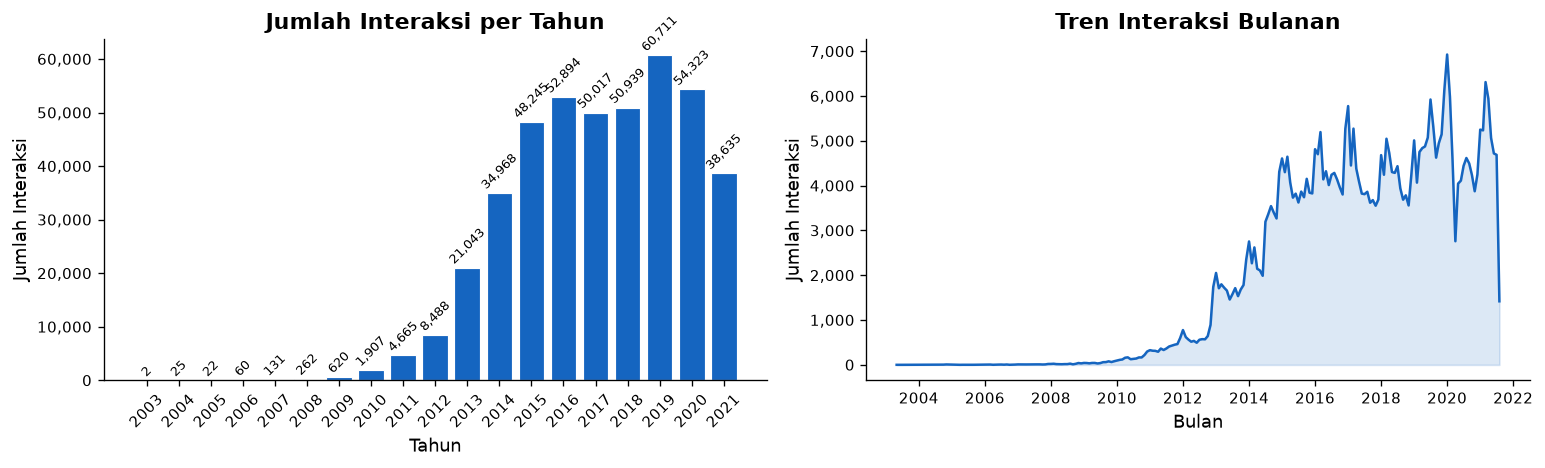

Tahun dengan interaksi terbanyak: 2019 (60,711 interaksi).


In [10]:
yearly = train.groupby(train['datetime'].dt.year).size().rename('interactions')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Per tahun
bars = axes[0].bar(
    yearly.index.astype(str), yearly.values,
    color='#1565c0', edgecolor='white', linewidth=0.7
)
for bar, val in zip(bars, yearly.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200,
        f'{val:,}', ha='center', va='bottom', fontsize=7.5, rotation=45
    )
axes[0].set_title('Jumlah Interaksi per Tahun', fontweight='bold')
axes[0].set_xlabel('Tahun')
axes[0].set_ylabel('Jumlah Interaksi')
axes[0].tick_params(axis='x', rotation=45)
axes[0].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f'{int(x):,}')
)

# Tren bulanan
monthly = train.groupby(train['datetime'].dt.to_period('M')).size()
monthly.index = monthly.index.to_timestamp()
axes[1].plot(monthly.index, monthly.values, color='#1565c0', linewidth=1.5)
axes[1].fill_between(monthly.index, monthly.values, alpha=0.15, color='#1565c0')
axes[1].set_title('Tren Interaksi Bulanan', fontweight='bold')
axes[1].set_xlabel('Bulan')
axes[1].set_ylabel('Jumlah Interaksi')
axes[1].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f'{int(x):,}')
)

plt.tight_layout()
plt.show()

top_year = yearly.idxmax()
print(f'Tahun dengan interaksi terbanyak: {top_year} ({yearly[top_year]:,} interaksi).')

---
## 7. Analisis Pengguna

Analisis pola aktivitas pengguna: distribusi jumlah interaksi per pengguna dan indikasi masalah *cold-start* user.

In [11]:
user_activity = train.groupby('user_id').size().rename('n_interactions')

print('=== Statistik Aktivitas per Pengguna ===')
display(user_activity.describe().to_frame('n_interactions').T)

for p in [90, 95, 99]:
    print(f'  Persentil {p:2d}: {np.percentile(user_activity, p):.0f} interaksi')

=== Statistik Aktivitas per Pengguna ===


,count,mean,std,min,25%,50%,75%,max
n_interactions,54483.0,7.854872,6.546081,1.0,5.0,6.0,9.0,270.0


  Persentil 90: 13 interaksi
  Persentil 95: 18 interaksi
  Persentil 99: 34 interaksi


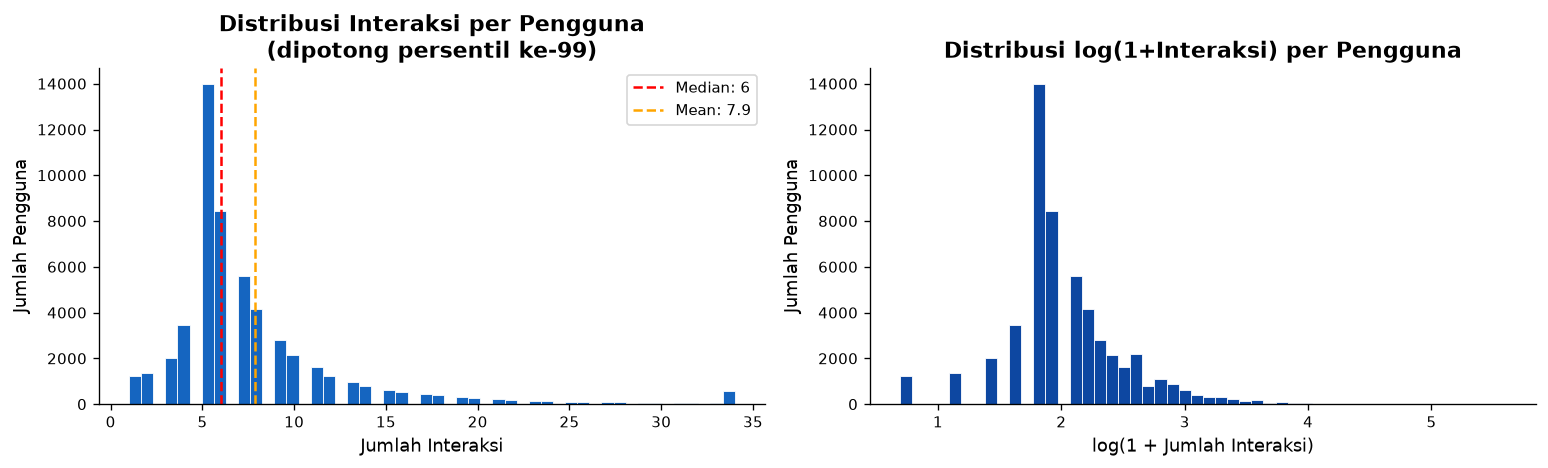

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

cap = user_activity.quantile(0.99)
axes[0].hist(user_activity.clip(upper=cap), bins=50,
             color='#1565c0', edgecolor='white', linewidth=0.5)
axes[0].set_title('Distribusi Interaksi per Pengguna\n(dipotong persentil ke-99)',
                  fontweight='bold')
axes[0].set_xlabel('Jumlah Interaksi')
axes[0].set_ylabel('Jumlah Pengguna')
axes[0].axvline(user_activity.median(), color='red', linestyle='--', linewidth=1.5,
                label=f'Median: {user_activity.median():.0f}')
axes[0].axvline(user_activity.mean(), color='orange', linestyle='--', linewidth=1.5,
                label=f'Mean: {user_activity.mean():.1f}')
axes[0].legend(fontsize=9)

axes[1].hist(np.log1p(user_activity), bins=50,
             color='#0d47a1', edgecolor='white', linewidth=0.5)
axes[1].set_title('Distribusi log(1+Interaksi) per Pengguna', fontweight='bold')
axes[1].set_xlabel('log(1 + Jumlah Interaksi)')
axes[1].set_ylabel('Jumlah Pengguna')

plt.tight_layout()
plt.show()

In [13]:
print('=== Analisis Cold-Start Pengguna ===')
print(f'{"Threshold":>12} | {"Jumlah User":>15} | {"Persentase":>12}')
print('-' * 44)
for t in [1, 2, 3, 5, 10]:
    n   = (user_activity <= t).sum()
    pct = n / len(user_activity) * 100
    print(f'  <= {t:2d} interaksi | {n:>15,} | {pct:>10.1f}%')

user_pos_activity = (
    train[train['rating'] >= 4]
    .groupby('user_id').size()
    .reindex(user_activity.index, fill_value=0)
)
n_zero_pos = (user_pos_activity == 0).sum()
print(f'\nPengguna tanpa interaksi positif (rating >= 4): {n_zero_pos:,} '
      f'({n_zero_pos / len(user_activity) * 100:.1f}%)')
print()
print('Interpretasi:')
print('  Popularity baseline menguntungkan justru karena tidak memerlukan '
      'histori pengguna yang panjang, sehingga efektif untuk cold-start user.')

=== Analisis Cold-Start Pengguna ===
   Threshold |     Jumlah User |   Persentase
--------------------------------------------
  <=  1 interaksi |           1,248 |        2.3%
  <=  2 interaksi |           2,633 |        4.8%
  <=  3 interaksi |           4,662 |        8.6%
  <=  5 interaksi |          22,117 |       40.6%
  <= 10 interaksi |          45,292 |       83.1%

Pengguna tanpa interaksi positif (rating >= 4): 447 (0.8%)

Interpretasi:
  Popularity baseline menguntungkan justru karena tidak memerlukan histori pengguna yang panjang, sehingga efektif untuk cold-start user.


---
## 8. Analisis Item & Long-Tail

Distribusi interaksi per item biasanya mengikuti distribusi **power law**: sejumlah kecil item (head) mendapat sebagian besar interaksi, sementara sebagian besar item (long-tail) hanya mendapat sedikit interaksi.

**Definisi long-tail dalam proyek ini:** item dengan jumlah interaksi training **≤ 5**.

In [14]:
item_activity = train.groupby('item_id').size().rename('n_interactions')

print('=== Statistik Aktivitas per Item ===')
display(item_activity.describe().to_frame('n_interactions').T)

for p in [75, 90, 95, 99]:
    print(f'  Persentil {p:2d}: {np.percentile(item_activity, p):.0f} interaksi')

=== Statistik Aktivitas per Item ===


,count,mean,std,min,25%,50%,75%,max
n_interactions,22753.0,18.808816,48.226975,1.0,5.0,8.0,17.0,2272.0


  Persentil 75: 17 interaksi
  Persentil 90: 36 interaksi
  Persentil 95: 60 interaksi
  Persentil 99: 170 interaksi


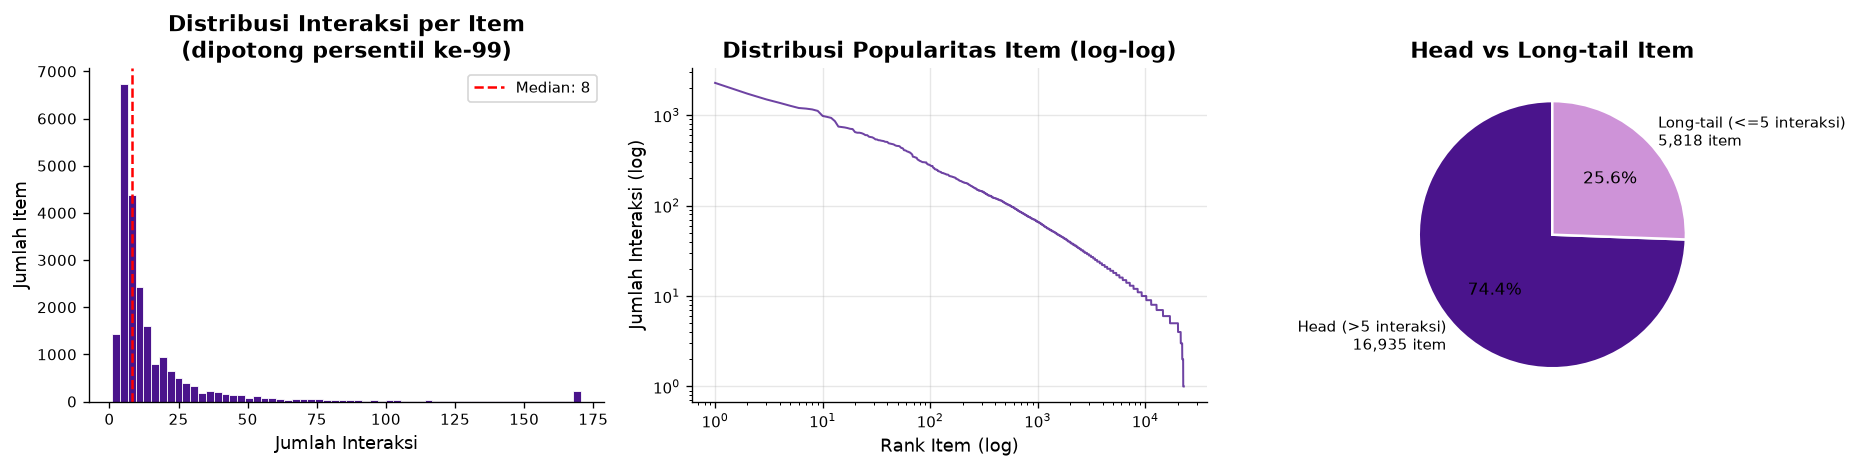

In [15]:
LONG_TAIL_THRESHOLD = 5  # sesuai definisi proyek

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Histogram
cap = item_activity.quantile(0.99)
axes[0].hist(item_activity.clip(upper=cap), bins=60,
             color='#4a148c', edgecolor='white', linewidth=0.5)
axes[0].set_title('Distribusi Interaksi per Item\n(dipotong persentil ke-99)',
                  fontweight='bold')
axes[0].set_xlabel('Jumlah Interaksi')
axes[0].set_ylabel('Jumlah Item')
axes[0].axvline(item_activity.median(), color='red', linestyle='--', linewidth=1.5,
                label=f'Median: {item_activity.median():.0f}')
axes[0].legend(fontsize=9)

# Log-log plot
sorted_counts = item_activity.sort_values(ascending=False).reset_index(drop=True)
axes[1].loglog(sorted_counts.index + 1, sorted_counts.values,
               color='#4a148c', linewidth=1.2, alpha=0.8)
axes[1].set_title('Distribusi Popularitas Item (log-log)', fontweight='bold')
axes[1].set_xlabel('Rank Item (log)')
axes[1].set_ylabel('Jumlah Interaksi (log)')
axes[1].grid(True, alpha=0.3)

# Head vs Long-tail pie
n_longtail = (item_activity <= LONG_TAIL_THRESHOLD).sum()
n_head     = (item_activity >  LONG_TAIL_THRESHOLD).sum()
axes[2].pie(
    [n_head, n_longtail],
    labels=[f'Head (>5 interaksi)\n{n_head:,} item',
            f'Long-tail (<=5 interaksi)\n{n_longtail:,} item'],
    colors=['#4a148c', '#ce93d8'], autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(linewidth=1.5, edgecolor='white')
)
axes[2].set_title('Head vs Long-tail Item', fontweight='bold')

plt.tight_layout()
plt.show()

In [16]:
longtail_mask = item_activity <= LONG_TAIL_THRESHOLD
n_longtail    = longtail_mask.sum()
pct_longtail  = n_longtail / len(item_activity) * 100
interactions_longtail = item_activity[longtail_mask].sum()
pct_interactions_lt   = interactions_longtail / item_activity.sum() * 100

# Aturan 80/20
n_head_20    = max(1, int(np.ceil(len(item_activity) * 0.20)))
head_items_20 = item_activity.nlargest(n_head_20)
share_head_20 = head_items_20.sum() / item_activity.sum() * 100

print(f'=== Analisis Long-tail Item ===')
print(f'Definisi long-tail: <= {LONG_TAIL_THRESHOLD} interaksi di training')
print()
print(f'Jumlah item long-tail    : {n_longtail:,} dari {len(item_activity):,} item '
      f'({pct_longtail:.1f}%)')
print(f'Interaksi dari long-tail : {interactions_longtail:,} dari {item_activity.sum():,} '
      f'({pct_interactions_lt:.1f}%)')
print(f'\nAturan 80/20:')
print(f'  20% item paling aktif ({n_head_20:,} item) => {share_head_20:.1f}% total interaksi')
print()
print('Interpretasi:')
print('  Ketimpangan distribusi interaksi mengonfirmasi pola power law.'
      ' Popularity baseline cenderung hanya merekomendasikan item dari head'
      ' dan mengabaikan long-tail.')

=== Analisis Long-tail Item ===
Definisi long-tail: <= 5 interaksi di training

Jumlah item long-tail    : 5,818 dari 22,753 item (25.6%)
Interaksi dari long-tail : 24,009 dari 427,957 (5.6%)

Aturan 80/20:
  20% item paling aktif (4,551 item) => 65.0% total interaksi

Interpretasi:
  Ketimpangan distribusi interaksi mengonfirmasi pola power law. Popularity baseline cenderung hanya merekomendasikan item dari head dan mengabaikan long-tail.


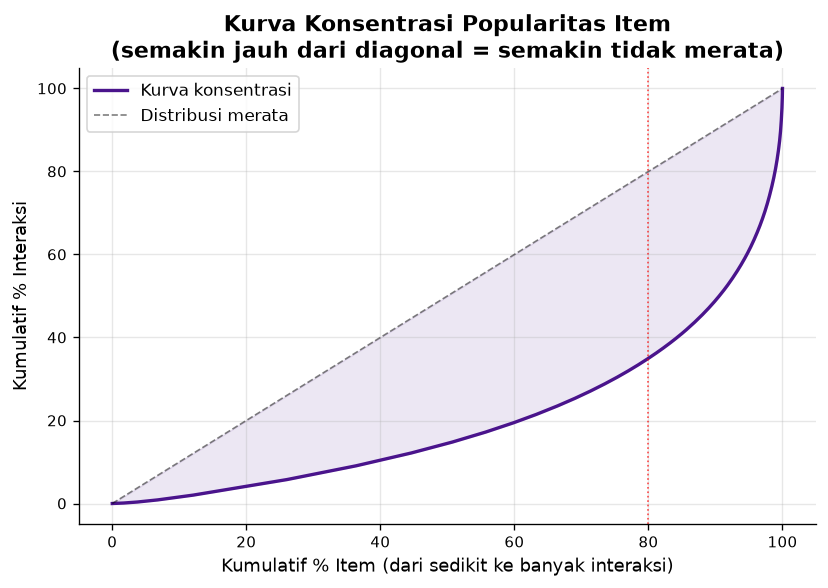

In [17]:
# Kurva konsentrasi popularitas (Lorenz-style)
sorted_counts_asc = item_activity.sort_values()
cum_items  = np.arange(1, len(sorted_counts_asc) + 1) / len(sorted_counts_asc)
cum_inters = sorted_counts_asc.cumsum() / sorted_counts_asc.sum()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(cum_items * 100, cum_inters * 100, color='#4a148c', linewidth=2,
        label='Kurva konsentrasi')
ax.plot([0, 100], [0, 100], 'k--', linewidth=1, alpha=0.5, label='Distribusi merata')
ax.fill_between(cum_items * 100, cum_inters * 100, cum_items * 100,
                alpha=0.1, color='#4a148c')
ax.axvline(80, color='red', linestyle=':', linewidth=1, alpha=0.7)
ax.set_title('Kurva Konsentrasi Popularitas Item\n'
             '(semakin jauh dari diagonal = semakin tidak merata)',
             fontweight='bold')
ax.set_xlabel('Kumulatif % Item (dari sedikit ke banyak interaksi)')
ax.set_ylabel('Kumulatif % Interaksi')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 9. Sparsity & Analisis Matriks Interaksi

**Sparsity** adalah proporsi pasangan (user, item) yang tidak memiliki interaksi. Tingkat sparsity yang tinggi adalah tantangan utama dalam sistem rekomendasi.

In [18]:
n_users_tr      = train['user_id'].nunique()
n_items_tr      = train['item_id'].nunique()
possible_pairs  = n_users_tr * n_items_tr
observed_pairs  = train[['user_id', 'item_id']].drop_duplicates().shape[0]
sparsity        = 1 - observed_pairs / possible_pairs
density         = observed_pairs / possible_pairs

print('=== Sparsity Matriks Interaksi ===')
print(f'  Jumlah pengguna               : {n_users_tr:,}')
print(f'  Jumlah item                   : {n_items_tr:,}')
print(f'  Total pasangan (user x item)  : {possible_pairs:,}')
print(f'  Pasangan yang terobservasi    : {observed_pairs:,}')
print(f'  Sparsity                      : {sparsity:.6f} ({sparsity * 100:.4f}%)')
print(f'  Density                       : {density:.6f} ({density * 100:.4f}%)')
print()
print('Interpretasi:')
print(f'  Matriks interaksi sangat sparse: hanya {density * 100:.4f}% dari'
      f' seluruh pasangan (user, item) terobservasi.')
print('  Tingginya sparsity mendukung penggunaan popularity baseline sebagai'
      ' fallback yang kuat karena tidak bergantung pada histori per-pengguna.')

=== Sparsity Matriks Interaksi ===
  Jumlah pengguna               : 54,483
  Jumlah item                   : 22,753
  Total pasangan (user x item)  : 1,239,651,699
  Pasangan yang terobservasi    : 427,957
  Sparsity                      : 0.999655 (99.9655%)
  Density                       : 0.000345 (0.0345%)

Interpretasi:
  Matriks interaksi sangat sparse: hanya 0.0345% dari seluruh pasangan (user, item) terobservasi.
  Tingginya sparsity mendukung penggunaan popularity baseline sebagai fallback yang kuat karena tidak bergantung pada histori per-pengguna.


---
## 10. Analisis Popularitas

Popularity baseline menggunakan **jumlah interaksi positif unik (rating ≥ 4)** sebagai ukuran popularitas item. Bagian ini menganalisis distribusi skor popularitas, item terpopuler, dan perbandingan metrik popularitas alternatif.

In [19]:
# Hitung skor popularitas
# Definisi: jumlah pengguna unik yang memberikan rating >= 4.
# Deduplikasi (user, item) agar review ganda tidak mendistorsi skor.
work = train.dropna(subset=['user_id', 'item_id', 'rating']).copy()
work['rating'] = pd.to_numeric(work['rating'], errors='coerce')
work = work.dropna(subset=['rating'])

positives       = work.loc[work['rating'] >= 4]
positive_unique = positives[['user_id', 'item_id']].drop_duplicates()

popularity = (
    positive_unique.groupby('item_id').size()
    .rename('positive_interactions')
    .reset_index()
)

all_items  = work[['item_id']].drop_duplicates()
popularity = all_items.merge(popularity, on='item_id', how='left')
popularity['positive_interactions'] = (
    popularity['positive_interactions'].fillna(0).astype(int)
)
popularity = popularity.sort_values(
    ['positive_interactions', 'item_id'],
    ascending=[False, True], kind='stable'
).reset_index(drop=True)

print('=== Ringkasan Skor Popularitas ===')
print(f'Total item           : {len(popularity):,}')
print(f'Item dengan skor > 0 : {(popularity["positive_interactions"] > 0).sum():,}')
print(f'Item dengan skor = 0 : {(popularity["positive_interactions"] == 0).sum():,}')
print(f'Skor maksimum        : {popularity["positive_interactions"].max():,}')
print(f'Skor median          : {popularity["positive_interactions"].median():.1f}')
print(f'Skor mean            : {popularity["positive_interactions"].mean():.2f}')

=== Ringkasan Skor Popularitas ===
Total item           : 22,753
Item dengan skor > 0 : 22,672


Item dengan skor = 0 : 81
Skor maksimum        : 2,175
Skor median          : 7.0
Skor mean            : 16.15


In [20]:
print('=== Top 20 Item Berdasarkan Interaksi Positif ===')
display(popularity.head(20).reset_index(drop=True))

=== Top 20 Item Berdasarkan Interaksi Positif ===


,item_id,positive_interactions
0,B09857JRP2,2175
1,B0BCK6L7S5,1441
2,B0BSGM6CQ9,1404
3,B0BPJ4Q6FJ,1271
4,B0BTC9YJ2W,1185
5,B004XNK7AI,1119
6,B0BHSG5C3G,1031
7,B08R5GM6YB,1002
8,B0C67HCGBR,917
9,B0BPLFP5P6,895


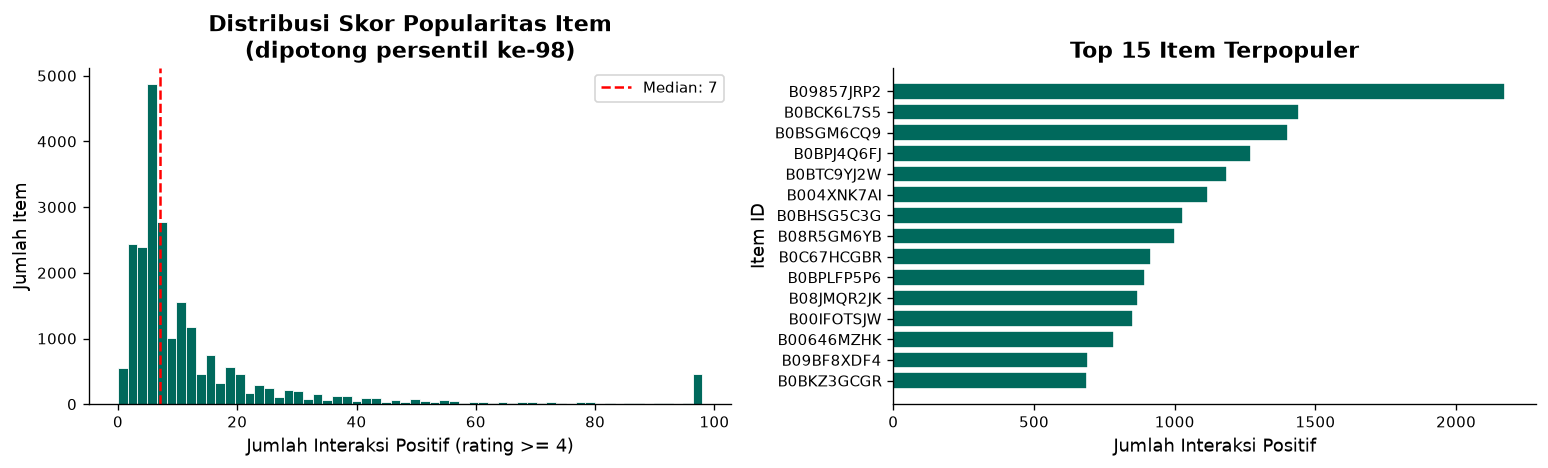

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram skor popularitas
cap = popularity['positive_interactions'].quantile(0.98)
axes[0].hist(
    popularity['positive_interactions'].clip(upper=cap),
    bins=60, color='#00695c', edgecolor='white', linewidth=0.5
)
axes[0].set_title('Distribusi Skor Popularitas Item\n(dipotong persentil ke-98)',
                  fontweight='bold')
axes[0].set_xlabel('Jumlah Interaksi Positif (rating >= 4)')
axes[0].set_ylabel('Jumlah Item')
axes[0].axvline(popularity['positive_interactions'].median(),
                color='red', linestyle='--', linewidth=1.5,
                label=f'Median: {popularity["positive_interactions"].median():.0f}')
axes[0].legend(fontsize=9)

# Bar chart top-15
top15 = popularity.head(15).copy()
axes[1].barh(
    top15['item_id'].str[-10:],
    top15['positive_interactions'],
    color='#00695c', edgecolor='white'
)
axes[1].set_title('Top 15 Item Terpopuler', fontweight='bold')
axes[1].set_xlabel('Jumlah Interaksi Positif')
axes[1].set_ylabel('Item ID')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

In [22]:
# Perbandingan metrik popularitas alternatif
pop_all        = work.groupby('item_id').size().rename('all_interactions')
pop_avg_rating = work.groupby('item_id')['rating'].mean().rename('avg_rating')
pop_pos        = popularity.set_index('item_id')['positive_interactions']

pop_compare = pd.concat([pop_all, pop_pos, pop_avg_rating], axis=1).fillna(0)
pop_compare.columns = ['all_interactions', 'positive_interactions', 'avg_rating']

print('=== Korelasi Antar Metrik Popularitas ===')
display(pop_compare.corr().round(4))

print()
print('Interpretasi:')
print('  Korelasi tinggi antara all_interactions dan positive_interactions'
      ' => item yang banyak diulas juga banyak mendapat rating positif.')
print('  Korelasi lemah antara jumlah interaksi dan avg_rating'
      ' => popularitas != kualitas rata-rata item.')

=== Korelasi Antar Metrik Popularitas ===


,all_interactions,positive_interactions,avg_rating
all_interactions,1.0000,0.9967,0.0360
positive_interactions,0.9967,1.0000,0.0691
avg_rating,0.0360,0.0691,1.0000



Interpretasi:
  Korelasi tinggi antara all_interactions dan positive_interactions => item yang banyak diulas juga banyak mendapat rating positif.
  Korelasi lemah antara jumlah interaksi dan avg_rating => popularitas != kualitas rata-rata item.


---
## 11. Analisis Candidate Set & Data Validasi

Bagian ini menganalisis:
- **Candidate set** (`candidate_items_warm.csv`): item kandidat rekomendasi
- **Data validasi** (`interactions_validation.csv`): distribusi dan perbandingan dengan training

In [23]:
# Load candidate set
try:
    cand_path = find_file('candidate_items_warm.csv')
    candidates_df = pd.read_csv(cand_path)
    candidates = set(candidates_df['item_id'].astype(str))
    print(f'Candidate set: {cand_path}')
    print(f'Jumlah kandidat item: {len(candidates):,}')

    train_items = set(train['item_id'].astype(str))
    overlap     = candidates & train_items
    only_cand   = candidates - train_items
    only_train  = train_items - candidates

    print(f'\n=== Coverage Candidate Set vs Training ===')
    print(f'  Item di kandidat DAN training    : {len(overlap):,} '
          f'({len(overlap)/len(candidates)*100:.1f}% dari kandidat)')
    print(f'  Item di kandidat TIDAK di training: {len(only_cand):,}')
    print(f'  Item di training TIDAK di kandidat: {len(only_train):,}')
    print()
    print('Candidate set merupakan warm items (sudah muncul di training).')
except FileNotFoundError:
    print('candidate_items_warm.csv tidak ditemukan; bagian ini dilewati.')
    candidates = None

Candidate set: data\candidate_items_warm.csv
Jumlah kandidat item: 22,753

=== Coverage Candidate Set vs Training ===
  Item di kandidat DAN training    : 22,753 (100.0% dari kandidat)
  Item di kandidat TIDAK di training: 0
  Item di training TIDAK di kandidat: 0

Candidate set merupakan warm items (sudah muncul di training).


Data validasi: data\interactions_validation.csv
Dimensi: 41,284 baris x 4 kolom



=== Perbandingan Train vs Validasi ===
Metrik                                        Train   Validasi
--------------------------------------------------------------
Jumlah interaksi                            427,957     41,284
Jumlah pengguna unik                         54,483     15,748
Jumlah item unik                             22,753     11,381
Rata-rata interaksi/pengguna                   7.85       2.62

Pengguna di keduanya: 14,175 (90.0% dari pengguna validasi)
Interaksi positif (rating >= 4) di validasi: 82.3%


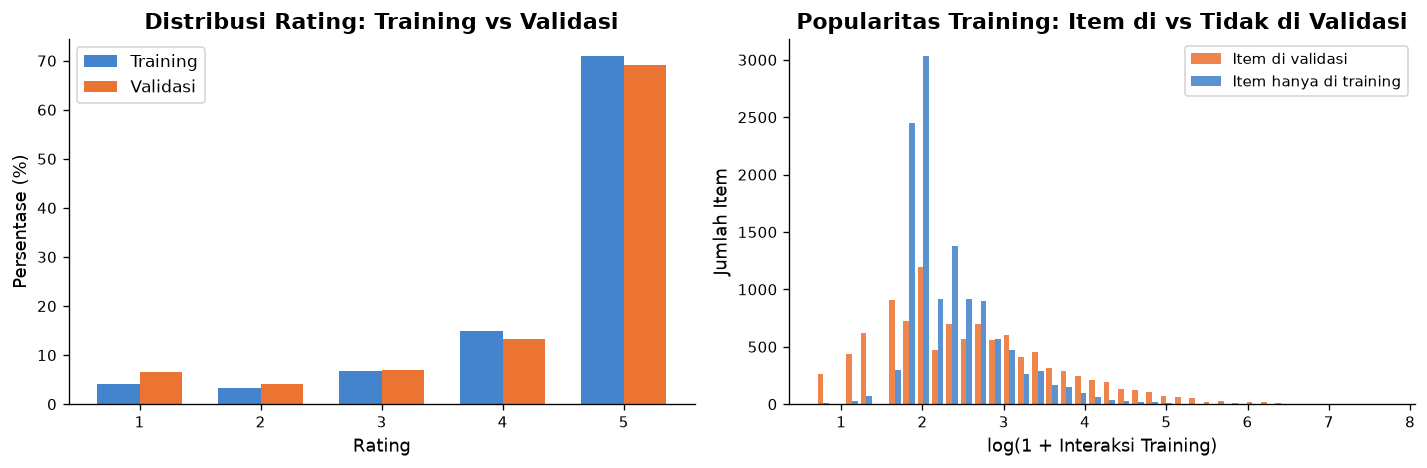

In [24]:
# Load dan analisis data validasi
try:
    val_path = find_file('interactions_validation.csv')
    val = pd.read_csv(val_path)
    print(f'Data validasi: {val_path}')
    print(f'Dimensi: {val.shape[0]:,} baris x {val.shape[1]} kolom')

    val_users   = set(val['user_id'].astype(str))
    train_users = set(train['user_id'].astype(str))

    print(f'\n=== Perbandingan Train vs Validasi ===')
    hdr = f'{"Metrik":<40} {"Train":>10} {"Validasi":>10}'
    print(hdr)
    print('-' * 62)
    print(f'{"Jumlah interaksi":<40} {len(train):>10,} {len(val):>10,}')
    print(f'{"Jumlah pengguna unik":<40} {train["user_id"].nunique():>10,} '
          f'{val["user_id"].nunique():>10,}')
    print(f'{"Jumlah item unik":<40} {train["item_id"].nunique():>10,} '
          f'{val["item_id"].nunique():>10,}')
    print(f'{"Rata-rata interaksi/pengguna":<40} '
          f'{len(train)/train["user_id"].nunique():>10.2f} '
          f'{len(val)/val["user_id"].nunique():>10.2f}')

    overlap_users = train_users & val_users
    print(f'\nPengguna di keduanya: {len(overlap_users):,} '
          f'({len(overlap_users)/len(val_users)*100:.1f}% dari pengguna validasi)')

    val_pct_positive = (val['rating'] >= 4).mean() * 100
    print(f'Interaksi positif (rating >= 4) di validasi: {val_pct_positive:.1f}%')

    # Visualisasi perbandingan distribusi rating
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    train_rpct = (train['rating'].value_counts().sort_index() / len(train) * 100)
    val_rpct   = (val['rating'].value_counts().sort_index() / len(val) * 100)

    x = np.arange(1, 6); width = 0.35
    axes[0].bar(x - width/2, [train_rpct.get(r, 0) for r in x], width,
                label='Training', color='#1565c0', alpha=0.8)
    axes[0].bar(x + width/2, [val_rpct.get(r, 0) for r in x], width,
                label='Validasi', color='#e65100', alpha=0.8)
    axes[0].set_title('Distribusi Rating: Training vs Validasi', fontweight='bold')
    axes[0].set_xlabel('Rating')
    axes[0].set_ylabel('Persentase (%)')
    axes[0].set_xticks(x)
    axes[0].legend()

    val_item_set = set(val['item_id'].astype(str))
    item_in_val  = item_activity.index.isin(val_item_set)
    axes[1].hist(
        [np.log1p(item_activity[item_in_val]),
         np.log1p(item_activity[~item_in_val])],
        bins=40, label=['Item di validasi', 'Item hanya di training'],
        color=['#e65100', '#1565c0'], alpha=0.7, stacked=False
    )
    axes[1].set_title('Popularitas Training: Item di vs Tidak di Validasi',
                      fontweight='bold')
    axes[1].set_xlabel('log(1 + Interaksi Training)')
    axes[1].set_ylabel('Jumlah Item')
    axes[1].legend(fontsize=9)

    plt.tight_layout()
    plt.show()

except FileNotFoundError:
    print('interactions_validation.csv tidak ditemukan; bagian ini dilewati.')
    val = None

---
## 12. Hubungan Antarvariabel

Analisis korelasi antara berbagai karakteristik item yang relevan dengan model rekomendasi.

=== Matriks Korelasi Fitur Item ===


,n_interactions,positive_interactions,avg_rating,n_unique_users,pct_positive
n_interactions,1.000,0.997,0.036,1.000,0.034
positive_interactions,0.997,1.000,0.069,0.997,0.069
avg_rating,0.036,0.069,1.000,0.036,0.923
n_unique_users,1.000,0.997,0.036,1.000,0.034
pct_positive,0.034,0.069,0.923,0.034,1.000


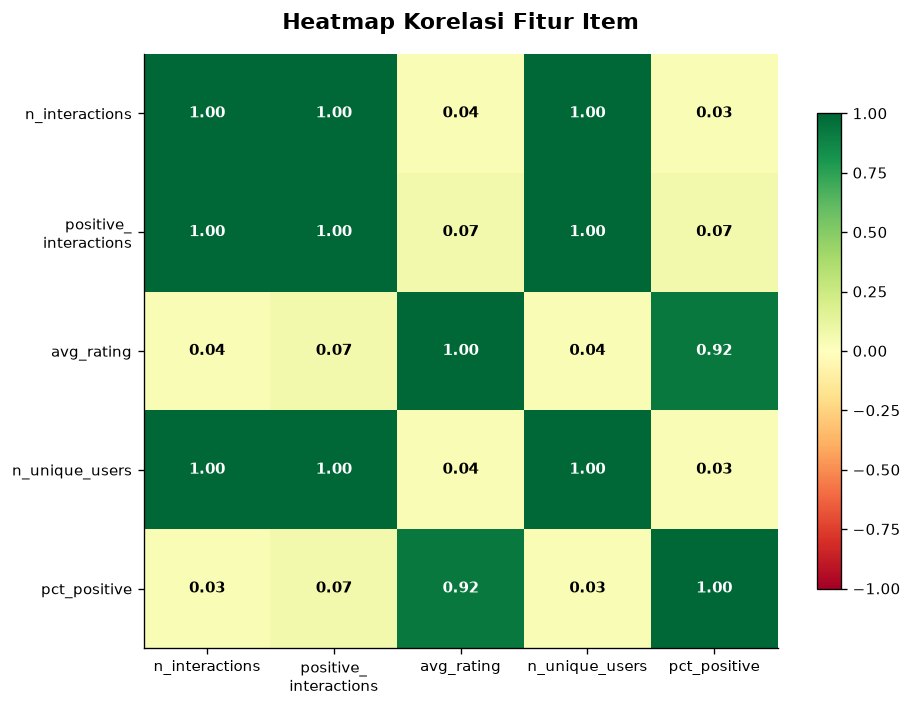

In [25]:
item_features = pd.DataFrame({
    'n_interactions'       : item_activity,
    'positive_interactions': pop_pos,
    'avg_rating'           : pop_avg_rating,
    'n_unique_users'       : train.groupby('item_id')['user_id'].nunique(),
}).fillna(0)

item_features['pct_positive'] = (
    item_features['positive_interactions'] / item_features['n_interactions']
).fillna(0)
item_features['log_n_interactions'] = np.log1p(item_features['n_interactions'])

corr_cols = ['n_interactions', 'positive_interactions', 'avg_rating',
             'n_unique_users', 'pct_positive']
corr_matrix = item_features[corr_cols].corr()

print('=== Matriks Korelasi Fitur Item ===')
display(corr_matrix.round(3))

# Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr_matrix.values, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, shrink=0.8)

labels = ['n_interactions', 'positive_\ninteractions', 'avg_rating',
          'n_unique_users', 'pct_positive']
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(labels, fontsize=9)
ax.set_yticklabels(labels, fontsize=9)

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr_matrix.values[i, j]
        color = 'white' if abs(val) > 0.6 else 'black'
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                fontsize=9, color=color, fontweight='bold')

ax.set_title('Heatmap Korelasi Fitur Item', fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

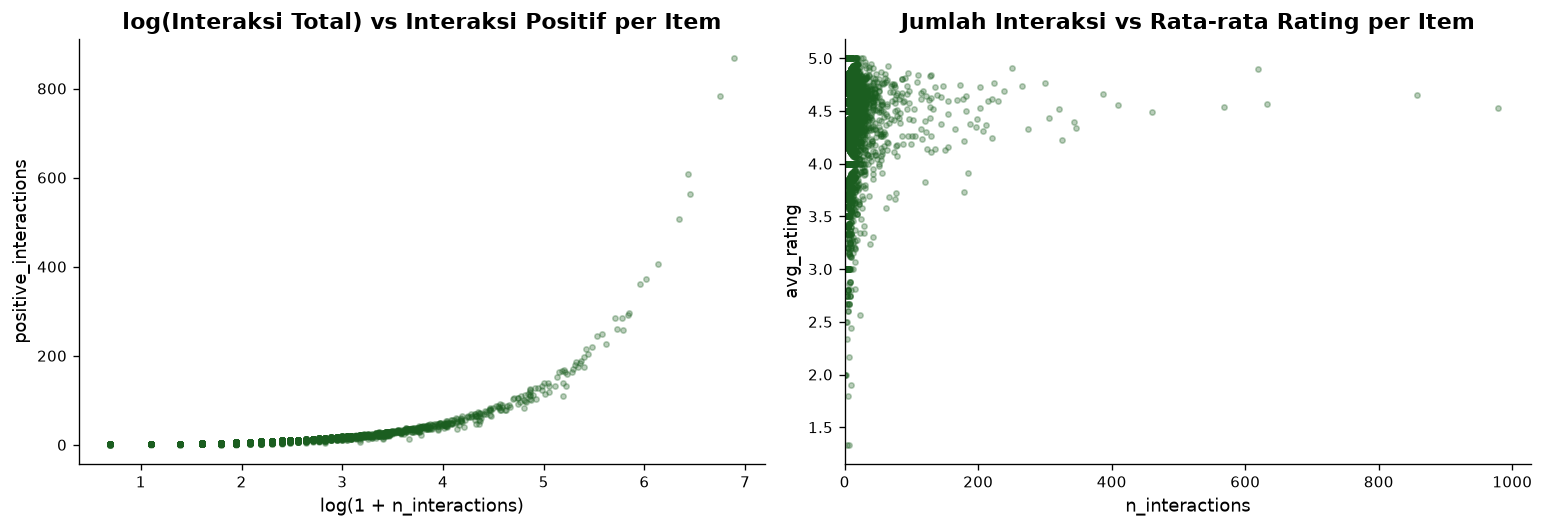

Interpretasi:
  Korelasi sangat tinggi antara total dan positif => sejalan.
  Korelasi lemah antara jumlah interaksi dan avg_rating => popularitas != kualitas rata-rata.


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sample = item_features.sample(min(3000, len(item_features)), random_state=42)

axes[0].scatter(sample['log_n_interactions'], sample['positive_interactions'],
                alpha=0.3, s=10, color='#1b5e20')
axes[0].set_title('log(Interaksi Total) vs Interaksi Positif per Item',
                  fontweight='bold')
axes[0].set_xlabel('log(1 + n_interactions)')
axes[0].set_ylabel('positive_interactions')

axes[1].scatter(sample['n_interactions'], sample['avg_rating'],
                alpha=0.3, s=10, color='#1b5e20')
axes[1].set_title('Jumlah Interaksi vs Rata-rata Rating per Item',
                  fontweight='bold')
axes[1].set_xlabel('n_interactions')
axes[1].set_ylabel('avg_rating')
axes[1].set_xlim(left=0)

plt.tight_layout()
plt.show()

print('Interpretasi:')
print('  Korelasi sangat tinggi antara total dan positif => sejalan.')
print('  Korelasi lemah antara jumlah interaksi dan avg_rating'
      ' => popularitas != kualitas rata-rata.')

---
## 13. Ringkasan Temuan Utama

In [27]:
print('=' * 65)
print('  RINGKASAN TEMUAN UTAMA EDA')
print('  Popularity Baseline - Amazon Musical Instruments (5-core)')
print('=' * 65)
print()

n_users_s  = train['user_id'].nunique()
n_items_s  = train['item_id'].nunique()
n_inter_s  = len(train)
pct_lt_s   = (item_activity <= LONG_TAIL_THRESHOLD).mean() * 100
pct_r5_s   = (train['rating'] == 5.0).mean() * 100
pct_pos_s  = (train['rating'] >= 4).mean() * 100
density_s  = observed_pairs / (n_users_s * n_items_s)

print('1. UKURAN DATASET')
print(f'   - {n_inter_s:,} interaksi | {n_users_s:,} pengguna | {n_items_s:,} item')
print()
print('2. KUALITAS DATA')
print('   - Tidak ada missing value pada kolom wajib')
print('   - Semua nilai rating valid (1.0-5.0)')
print('   - Tidak ada duplikasi pasangan (user, item)')
print()
print('3. DISTRIBUSI RATING')
print(f'   - Rating 5 mendominasi ({pct_r5_s:.1f}%) => positivity bias kuat')
print(f'   - {pct_pos_s:.1f}% interaksi dianggap positif (rating >= 4)')
print()
print('4. AKTIVITAS PENGGUNA')
print(f'   - Rata-rata {n_inter_s/n_users_s:.1f} interaksi per pengguna, '
      f'median {train.groupby("user_id").size().median():.0f}')
print(f'   - Max {train.groupby("user_id").size().max():,} interaksi (super-aktif)')
print()
print('5. DISTRIBUSI ITEM (POWER LAW)')
print(f'   - {pct_lt_s:.1f}% item masuk kategori long-tail (<= 5 interaksi)')
print(f'   - 20% item paling aktif => {share_head_20:.1f}% total interaksi')
print()
print('6. SPARSITY')
print(f'   - Density matriks: {density_s:.4f} ({density_s * 100:.4f}%)')
print(f'   - Sangat sparse; popularity baseline efektif sebagai fallback')
print()
print('7. POPULARITAS')
print(f'   - Skor max: {popularity["positive_interactions"].max():,} interaksi positif')
print(f'   - Median skor: {popularity["positive_interactions"].median():.0f} (ketimpangan ekstrem)')
print()
print('8. KORELASI')
print('   - Korelasi tinggi: total interaksi vs interaksi positif')
print('   - Korelasi lemah : jumlah interaksi vs rata-rata rating')

  RINGKASAN TEMUAN UTAMA EDA
  Popularity Baseline - Amazon Musical Instruments (5-core)

1. UKURAN DATASET
   - 427,957 interaksi | 54,483 pengguna | 22,753 item

2. KUALITAS DATA
   - Tidak ada missing value pada kolom wajib
   - Semua nilai rating valid (1.0-5.0)
   - Tidak ada duplikasi pasangan (user, item)

3. DISTRIBUSI RATING
   - Rating 5 mendominasi (70.9%) => positivity bias kuat
   - 85.9% interaksi dianggap positif (rating >= 4)

4. AKTIVITAS PENGGUNA
   - Rata-rata 7.9 interaksi per pengguna, median 6
   - Max 270 interaksi (super-aktif)

5. DISTRIBUSI ITEM (POWER LAW)
   - 25.6% item masuk kategori long-tail (<= 5 interaksi)
   - 20% item paling aktif => 65.0% total interaksi

6. SPARSITY
   - Density matriks: 0.0003 (0.0345%)
   - Sangat sparse; popularity baseline efektif sebagai fallback

7. POPULARITAS
   - Skor max: 2,175 interaksi positif
   - Median skor: 7 (ketimpangan ekstrem)

8. KORELASI
   - Korelasi tinggi: total interaksi vs interaksi positif
   - Korelasi 

---
## 14. Implikasi terhadap Popularity-Based Recommendation

Bagian ini mendiskusikan secara mendalam bagaimana hasil EDA memengaruhi desain, pemilihan metrik, keunggulan, dan keterbatasan *Popularity-Based Recommendation* dalam konteks proyek ini.

### 14.1 Kesesuaian Popularity Baseline dengan Karakteristik Dataset

| Temuan EDA | Implikasi terhadap Popularity Baseline |
|------------|----------------------------------------|
| Sparsity sangat tinggi (~99.97%) | CF berbasis kemiripan pengguna kesulitan; popularity sebagai fallback masuk akal |
| Median interaksi per pengguna rendah | Banyak pengguna terlalu sedikit histori untuk personalisasi akurat |
| Distribusi rating right-skewed (rating 5 dominan) | Sinyal positif kaya dan dapat diandalkan |
| Power law pada distribusi item | Prior bahwa item populer cenderung disukai secara umum |

### 14.2 Metrik Popularitas yang Digunakan

Proyek ini memilih **jumlah pengguna unik dengan rating ≥ 4** sebagai metrik popularitas:
- **Kualitas vs. kuantitas**: hanya interaksi positif yang dihitung
- **Robustness terhadap spam**: deduplikasi (user, item) mencegah distorsi
- **Interpretabilitas**: skor = "jumlah pengguna yang puas"

**Alternatif yang dapat dipertimbangkan di masa depan:**
- Wilson Score Interval (mempertimbangkan confidence berdasarkan volume ulasan)
- Bayesian Average (menyeimbangkan rating item dengan rata-rata global)
- Recency-weighted popularity (bobot lebih pada interaksi terbaru)

### 14.3 Keunggulan Popularity Baseline

1. **Zero cold-start user problem**: setiap pengguna baru langsung menerima rekomendasi
2. **Komputasi ringan**: dapat di-precompute sekali untuk semua pengguna
3. **Lower bound evaluasi**: model canggih harus mengalahkan popularity baseline
4. **Relevansi di domain niche**: item populer di kategori Musical Instruments cenderung berkualitas

### 14.4 Keterbatasan dan Risiko

1. **Nol personalisasi**: seluruh pengguna mendapat rekomendasi identik
2. **Long-tail exposure = 0**: item long-tail sama sekali tidak direkomendasikan
3. **Matthew Effect**: item populer semakin mendominasi, item baru semakin terpinggirkan
4. **Catalog coverage sangat rendah**: hanya ~18 item unik yang direkomendasikan ke semua pengguna
5. **Tidak sensitif terhadap konteks**: tidak mempertimbangkan preferensi genre atau demografi

### 14.5 Rekomendasi Pengembangan Selanjutnya

1. **Stratifikasi popularitas**: kombinasikan head dan long-tail untuk meningkatkan diversitas
2. **Popularity dengan konteks temporal**: hitung popularitas berdasarkan periode waktu tertentu
3. **Re-ranking berbasis long-tail**: tambahkan bonus untuk item long-tail (telah diimplementasikan di MF-reranked)
4. **Evaluasi coverage & fairness**: monitor diversity dan long-tail exposure secara eksplisit
5. **Hybrid approach**: popularity sebagai prior untuk cold-start, beralih ke personalisasi begitu histori pengguna mencukupi

In [28]:
# Tampilkan dan interpretasikan hasil metrik baseline dari outputs/w6/metrics.json
metrics_candidates = [
    Path('outputs/w6/metrics.json'),
    Path('/content/outputs/w6/metrics.json'),
]
metrics_path = next((p for p in metrics_candidates if p.exists()), None)

if metrics_path:
    with open(metrics_path, 'r', encoding='utf-8') as f:
        metrics = json.load(f)

    rows = []
    for model_name, model_metrics in metrics.items():
        row = {'Model': model_name}
        row.update(model_metrics)
        rows.append(row)

    metrics_df = pd.DataFrame(rows).set_index('Model')
    print('=' * 65)
    print('  RINGKASAN METRIK BASELINE (outputs/w6/metrics.json)')
    print('=' * 65)
    display(metrics_df)

    print()
    print('=== Interpretasi Metrik ===')
    print()
    print('NDCG@10 (Normalized Discounted Cumulative Gain):')
    for m in ['popularity', 'mf', 'tfidf', 'mf_reranked']:
        print(f'  {m:<14}: {metrics[m]["ndcg@10"]:.4f}')
    print()
    print('Catalog Coverage@10:')
    print(f'  popularity : {metrics["popularity"]["catalog_coverage@10"]:.4%} '
          f'({metrics["popularity"]["catalog_items_recommended@10"]} item) - SANGAT RENDAH')
    print(f'  tfidf      : {metrics["tfidf"]["catalog_coverage@10"]:.4%} '
          f'({metrics["tfidf"]["catalog_items_recommended@10"]:,} item) - coverage terbaik')
    print()
    print('Long-tail Exposure@10:')
    print(f'  popularity : {metrics["popularity"]["long_tail_exposure@10"]:.4f} - nol sama sekali!')
    print(f'  tfidf      : {metrics["tfidf"]["long_tail_exposure@10"]:.4f} - exposure terbaik')
    print()
    print('Kesimpulan:')
    print('  Popularity baseline memiliki NDCG@10 tertinggi namun catalog coverage'
          ' dan long-tail exposure terendah. Ini mengonfirmasi temuan EDA: popularity'
          ' baseline sangat efisien secara akurasi jangka pendek tetapi berpotensi'
          ' merugikan ekosistem platform jangka panjang karena mengabaikan long-tail item.')
else:
    print('File outputs/w6/metrics.json tidak ditemukan.')
    print('Jalankan run_baselines.py terlebih dahulu untuk menghasilkan metrik.')

  RINGKASAN METRIK BASELINE (outputs/w6/metrics.json)


,ndcg@10,catalog_coverage@10,catalog_items_recommended@10,average_item_popularity@10,long_tail_exposure@10,users_evaluated
Model,,,,,,
popularity,0.009221,0.000791,18,1361.906203,0.000000,11850
mf,0.007827,0.009537,217,605.607494,0.000000,11850
tfidf,0.007293,0.717004,16314,35.716481,0.205662,11850
mf_reranked,0.007828,0.017932,408,602.819333,0.003586,11850



=== Interpretasi Metrik ===

NDCG@10 (Normalized Discounted Cumulative Gain):
  popularity    : 0.0092
  mf            : 0.0078
  tfidf         : 0.0073
  mf_reranked   : 0.0078

Catalog Coverage@10:
  popularity : 0.0791% (18 item) - SANGAT RENDAH
  tfidf      : 71.7004% (16,314 item) - coverage terbaik

Long-tail Exposure@10:
  popularity : 0.0000 - nol sama sekali!
  tfidf      : 0.2057 - exposure terbaik

Kesimpulan:
  Popularity baseline memiliki NDCG@10 tertinggi namun catalog coverage dan long-tail exposure terendah. Ini mengonfirmasi temuan EDA: popularity baseline sangat efisien secara akurasi jangka pendek tetapi berpotensi merugikan ekosistem platform jangka panjang karena mengabaikan long-tail item.


---

## Catatan Akhir

Notebook ini merupakan **EDA yang dikembangkan** dari notebook asli `Popularity_Baseline(baru3).ipynb`.

**File asli tidak diubah.** Semua pengembangan disimpan dalam file terpisah ini.

**Keterbatasan analisis yang belum dapat dijawab sepenuhnya:**
- Analisis konten item (judul, kategori, deskripsi) dari `items.csv` tidak diintegrasikan ke EDA umum karena ukuran file yang besar.
- Test set independen tidak tersedia; evaluasi hanya pada validation set.
- Analisis bias temporal yang lebih mendalam memerlukan time-series analysis lanjutan.

---
*Jalankan notebook dari atas ke bawah secara berurutan.* *Pastikan semua dataset tersedia di folder `data/` sebelum menjalankan.*